# Tema : Modelo LSTM

![](src/img/logo_utb.png)
![](src/img/logo_etd.png)
- **Profesor:**
- **Fernando Salcedo Mejía, Eco Msc.**
- Programa de Ciencias de Datos | Escuela de transformación digital.
- 2026-1

# Ejercicio 1. Demanda diaria de electricidad en Victoria, Australia

- Una aplicación común de estos modelos es el pronóstico de la demanda de electricidad. Tenemos la demanda de electricidad cada media hora (MWh) en Victoria, Australia, durante el periodo 2012-2014, junto con la temperatura (en grados Celsius) en Melbourne, la ciudad más grande de Victoria.
- Para este ejercicio agregamos los datos a frecuencia diaria. La demanda diaria es la suma de las demandas de cada media hora, expresada en GWh, y la temperatura diaria es la temperatura máxima del día.
- El objetivo es pronosticar la demanda de los últimos 90 días de 2014 con una red LSTM. Usamos los mismos datos y el mismo periodo de prueba del notebook de Prophet, de modo que los resultados de ambos notebooks se pueden comparar.

In [1]:
# Ocultar los mensajes informativos de TensorFlow
import os
os.environ["TF_CPP_MIN_LOG_LEVEL"] = "3"

# Librerias necesarias

# Datos
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

# Modelo LSTM
from sklearn.preprocessing import MinMaxScaler
import tensorflow as tf
from tensorflow import keras

import warnings
warnings.filterwarnings('ignore')

# Semilla para que los resultados sean reproducibles
keras.utils.set_random_seed(42)

I0000 00:00:1794926106.972067   45893 port.cc:153] oneDNN custom operations are on. You may see slightly different numerical results due to floating-point round-off errors from different computation orders. To turn them off, set the environment variable `TF_ENABLE_ONEDNN_OPTS=0`.
I0000 00:00:1794926106.972852   45893 cudart_stub.cc:31] Could not find cuda drivers on your machine, GPU will not be used.


I0000 00:00:1794926109.014331   45893 port.cc:153] oneDNN custom operations are on. You may see slightly different numerical results due to floating-point round-off errors from different computation orders. To turn them off, set the environment variable `TF_ENABLE_ONEDNN_OPTS=0`.
I0000 00:00:1794926109.014918   45893 cudart_stub.cc:31] Could not find cuda drivers on your machine, GPU will not be used.


## Datos

In [2]:
# datos de electricidad
github_data = "https://raw.githubusercontent.com/fersalme/regresion-lineal-series-tiempo/refs/heads/main/data/vic_elec.csv"
vic_elec = pd.read_csv(github_data, parse_dates=["ds"])

vic_elec_df = (
    vic_elec
    .pivot(index=["ds", "Holiday"], columns="unique_id", values="y")
    .reset_index().rename_axis(None, axis="columns")
    .assign(ds=lambda x: pd.to_datetime(x["ds"]).dt.normalize())
    .groupby(["ds", "Holiday"])
    .agg({
        "Demand": "sum",          # Demanda total del día
        "Temperature": "max"      # Temperatura máxima del día
    })
    .reset_index()
    .assign(
        Demand=lambda x: x["Demand"] / 1e3,                     # MWh a GWh
        Working_Day=lambda x: (~x["Holiday"] & ~x["ds"].dt.dayofweek.isin([5, 6])).astype(int),
    )
    .drop(columns=["Holiday"])
)

print(f"Número de días: {len(vic_elec_df)}")
vic_elec_df.head()

Número de días: 1096


,ds,Demand,Temperature,Working_Day
0,2012-01-01,222.437912,32.7,0
1,2012-01-02,257.964724,39.6,0
2,2012-01-03,267.098605,31.8,1
3,2012-01-04,222.742287,25.1,1
4,2012-01-05,210.585240,21.2,1


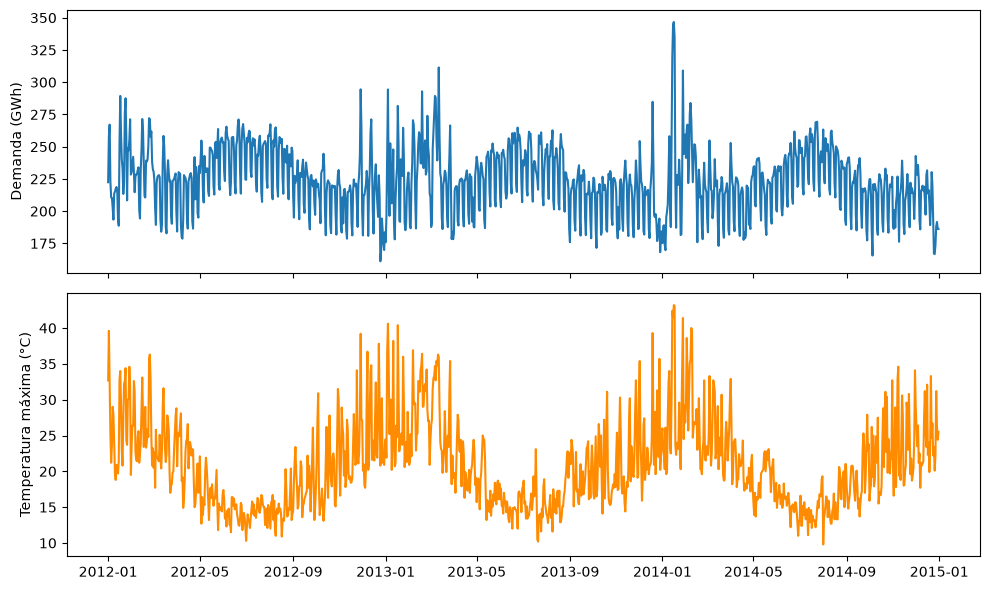

In [3]:
fig, axes = plt.subplots(2, 1, figsize=(10, 6), sharex=True)
axes[0].plot(vic_elec_df["ds"], vic_elec_df["Demand"])
axes[0].set_ylabel("Demanda (GWh)")
axes[1].plot(vic_elec_df["ds"], vic_elec_df["Temperature"], color="darkorange")
axes[1].set_ylabel("Temperatura máxima (°C)")
plt.tight_layout()
plt.show()

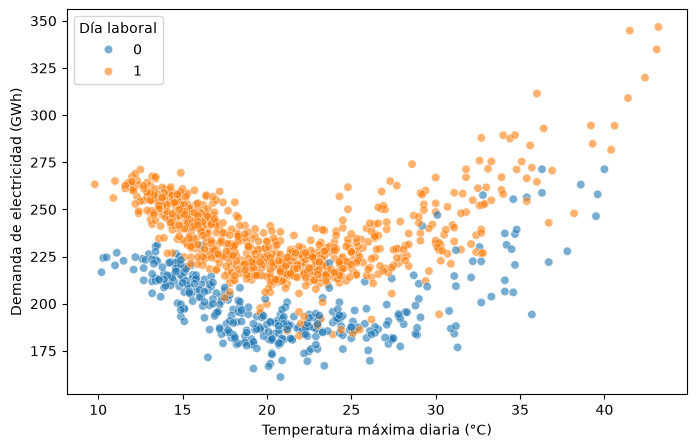

In [4]:
fig, ax = plt.subplots(figsize=(8, 5))
sns.scatterplot(data=vic_elec_df, x="Temperature", y="Demand",
    hue="Working_Day", palette="tab10", alpha=0.6, ax=ax)
ax.set(
    xlabel="Temperatura máxima diaria (°C)",
    ylabel="Demanda de electricidad (GWh)",
)
ax.legend(title="Día laboral")
plt.show()

Si se representa la demanda de electricidad en función de la temperatura, se observa una relación no lineal entre ambas. La demanda aumenta con las temperaturas bajas, por el uso de calefacción, y con las temperaturas altas, por el uso de aire acondicionado. Además, los días laborales tienen una demanda mayor que los fines de semana y festivos. Una red LSTM puede aprender esta relación no lineal sin que tengamos que especificar su forma.

## Modelo usando LSTM

### Pasos
1. Definir las variables de entrada y dividir los datos en entrenamiento y prueba respetando el orden del tiempo.
2. Escalar los datos entre 0 y 1, ajustando el escalamiento solo con el conjunto de entrenamiento.
3. Convertir la serie de tiempo en secuencias. Transformamos los datos en ventanas deslizantes que sirven de entrada a la LSTM.
4. Construir y entrenar el modelo LSTM con parada temprana.
5. Pronosticar el periodo de prueba a un paso y de forma recursiva, y comparar con un modelo de referencia.

## Variables de entrada

- La red usa como entrada la demanda, la temperatura máxima y el indicador de día laboral de los días anteriores.
- La temperatura y el tipo de día del día que se quiere pronosticar también son muy informativos. Para incluirlos en la ventana, desplazamos un día hacia atrás esas dos variables. Así, la fila del día $t$ contiene la demanda de $t$ y la temperatura y el tipo de día de $t+1$, y una ventana que termina en el día $t$ tiene toda la información disponible para pronosticar la demanda de $t+1$.
- Este es el mismo conjunto de información que usa el modelo Prophet con regresoras. Igual que en ese notebook, en el periodo de prueba usamos la temperatura observada, lo que se conoce como **pronóstico ex post**. En un pronóstico real se usaría el pronóstico del clima.

In [5]:
df = vic_elec_df.set_index("ds")[["Demand"]].copy()
df["Temperature_next"] = vic_elec_df.set_index("ds")["Temperature"].shift(-1)
df["Working_Day_next"] = vic_elec_df.set_index("ds")["Working_Day"].shift(-1)

# La última fila no tiene día siguiente. Esa fila nunca se usa como entrada de una ventana,
# solo como objetivo, por lo que se completa con ceros.
df = df.fillna(0)
df.head()

,Demand,Temperature_next,Working_Day_next
ds,,,
2012-01-01,222.437912,39.6,0.0
2012-01-02,257.964724,31.8,1.0
2012-01-03,267.098605,25.1,1.0
2012-01-04,222.742287,21.2,1.0
2012-01-05,210.585240,23.6,1.0


## Conjuntos de entrenamiento y prueba

- Reservamos los últimos 90 días como conjunto de prueba, igual que en el notebook de Prophet. La partición respeta el orden del tiempo, de forma que el modelo nunca usa información del periodo de prueba durante el entrenamiento.

In [6]:
h = 90                          # días del conjunto de prueba
n_total = len(df)
n_train = n_total - h           # número de días de entrenamiento

print(f"Entrenamiento: {df.index[0].date()} a {df.index[n_train - 1].date()} ({n_train} días)")
print(f"Prueba:        {df.index[n_train].date()} a {df.index[-1].date()} ({h} días)")

Entrenamiento: 2012-01-01 a 2014-10-02 (1006 días)
Prueba:        2014-10-03 a 2014-12-31 (90 días)


## Escalamiento de los datos

$$\hat{x}_i = \frac{x_i - x_{\min}}{x_{\max} - x_{\min}}$$

Donde

| Símbolo | Descripción |
|---------|-------------|
| $x_i$ | Valor original |
| $\hat{x}_i$ | Valor normalizado $\in [0, 1]$ |
| $x_{\min}$ | Mínimo de la serie en el conjunto de entrenamiento |
| $x_{\max}$ | Máximo de la serie en el conjunto de entrenamiento |

Para recuperar la escala original se usa la **transformación inversa**

$$x_i = \hat{x}_i \cdot (x_{\max} - x_{\min}) + x_{\min}$$

El mínimo y el máximo se calculan **solo con los datos de entrenamiento**. Si se calcularan con toda la serie, el escalamiento usaría información del periodo de prueba y el error de pronóstico resultaría optimista. Por esa razón, en el periodo de prueba algunos valores escalados pueden quedar por fuera del intervalo $[0, 1]$.

In [7]:
# Ajustar el escalamiento solo con el entrenamiento y aplicarlo a toda la serie
scaler = MinMaxScaler()
scaler.fit(df.iloc[:n_train])
scaled_data = scaler.transform(df)

print(f"Dimensión de la matriz: {scaled_data.shape}")
print("\nPrimeras filas de la matriz escalada")
for i in range(5):
    print(f"Fila {i} : {scaled_data[i].round(4)}")

Dimensión de la matriz: (1096, 3)

Primeras filas de la matriz escalada
Fila 0 : [0.3304 0.8922 0.    ]
Fila 1 : [0.5218 0.6587 1.    ]
Fila 2 : [0.571  0.4581 1.    ]
Fila 3 : [0.3321 0.3413 1.    ]
Fila 4 : [0.2666 0.4132 1.    ]


## Ventanas deslizantes

La serie de tiempo es

| $t_1$ | $t_2$ | $t_3$ | $t_4$ | $t_5$ | $t_6$ | $t_7$ | $t_8$ | $t_9$ | $t_{10}$ |
|:-----:|:-----:|:-----:|:-----:|:-----:|:-----:|:-----:|:-----:|:-----:|:------:|
| $y_1$ | $y_2$ | $y_3$ | $y_4$ | $y_5$ | $y_6$ | $y_7$ | $y_8$ | $y_9$ | $y_{10}$ |

Con tamaño de ventana 4 y horizonte 1 tenemos una secuencia que se desliza un paso a la vez

| Ventana (X) | | | | Objetivo (y) |
|:-----------:|:-----------:|:-----------:|:-----------:|:------------:|
| $y_1$ | $y_2$ | $y_3$ | $y_4$ | $y_5$ |
| $y_2$ | $y_3$ | $y_4$ | $y_5$ | $y_6$ |
| $y_3$ | $y_4$ | $y_5$ | $y_6$ | $y_7$ |
| $y_4$ | $y_5$ | $y_6$ | $y_7$ | $y_8$ |
| $y_5$ | $y_6$ | $y_7$ | $y_8$ | $y_9$ |
| $y_6$ | $y_7$ | $y_8$ | $y_9$ | $y_{10}$ |
| **paso 1** | **paso 2** | **paso 3** | **paso 4** | **horizonte** |

Cada ventana es una muestra para la red neuronal

| | **Muestra 1** | **Muestra 2** | **Muestra 3** | **Muestra 4** | **Muestra 5** | **Muestra 6** |
|:---:|:---:|:---:|:---:|:---:|:---:|:---:|
| paso 1 | $y_1$ | $y_2$ | $y_3$ | $y_4$ | $y_5$ | $y_6$ |
| paso 2 | $y_2$ | $y_3$ | $y_4$ | $y_5$ | $y_6$ | $y_7$ |
| paso 3 | $y_3$ | $y_4$ | $y_5$ | $y_6$ | $y_7$ | $y_8$ |
| paso 4 | $y_4$ | $y_5$ | $y_6$ | $y_7$ | $y_8$ | $y_9$ |
| **objetivo** | $y_5$ | $y_6$ | $y_7$ | $y_8$ | $y_9$ | $y_{10}$ |

Con `window_size = 4`, `horizon = 1` y una serie de $T = 10$ observaciones, el número de muestras es

$$n\_samples = T - window\_size - horizon + 1 = 10 - 4 - 1 + 1 = 6$$

y las dimensiones de los arreglos resultantes son

| Tensor | Dimensiones | Valores |
|--------|------------|---------|
| `X` | `(n_samples, window_size, n_features)` | `(6, 4, 1)` |
| `y` | `(n_samples, horizon)` | `(6, 1)` |

Un tensor es una generalización de los escalares, los vectores y las matrices a cualquier número de dimensiones.

| | **Escalar** | **Vector** | **Matriz** | **Tensor 3D** |
|---|:---:|:---:|:---:|:---:|
| **Ejes** | 0 | 1 | 2 | 3 |
| **Shape** | `()` | `(3,)` | `(3, 3)` | `(n, m, p)` |
| **Índice** | — | $x_i$ | $x_{ij}$ | $x_{ijk}$ |
| **Ejemplo** | $5$ | $[1, 2, 3]$ | $\begin{bmatrix}1&2&3\\4&5&6\\7&8&9\end{bmatrix}$ | $\mathbf{X}[i,j,k]$ |
| **En NumPy** | `np.array(5)` | `np.array([1,2,3])` | `np.zeros((3,3))` | `np.zeros((n,m,p))` |
| **En LSTM** | Un valor $y_t$ | Una ventana $[y_1 \dots y_w]$ | Ventanas de una variable | Ventanas de múltiples variables |

En este ejercicio usamos ventanas de 14 días, que cubren dos semanas completas, y tres variables por día.

In [8]:
# Crear secuencias de la serie
def create_sequences(data, window):
    X, y = [], []
    for i in range(len(data) - window):
        X.append(data[i:i + window])     # ventana de días i, ..., i + window - 1
        y.append(data[i + window, 0])    # demanda del día i + window (columna 0)
    return np.array(X), np.array(y)

window = 14
X, y = create_sequences(scaled_data, window)

# El objetivo de la muestra i es el día i + window
dia_objetivo = np.arange(len(X)) + window

print(f"X: {X.shape}  (muestras, pasos de tiempo, variables)")
print(f"y: {y.shape}")

X: (1082, 14, 3)  (muestras, pasos de tiempo, variables)
y: (1082,)


In [9]:
# Dividir en entrenamiento y prueba según el día objetivo
es_train = dia_objetivo < n_train

X_train, y_train = X[es_train], y[es_train]
X_test,  y_test  = X[~es_train], y[~es_train]

print(f"Muestras de entrenamiento: {len(X_train)}")
print(f"Muestras de prueba:        {len(X_test)}")

Muestras de entrenamiento: 992
Muestras de prueba:        90


## Construir el modelo LSTM

- La capa LSTM aprende los patrones temporales de la ventana.
- La capa de dropout apaga al azar el 20% de las neuronas en cada paso del entrenamiento para reducir el sobreajuste.
- La capa densa con activación lineal convierte el último estado oculto en el pronóstico de la demanda del día siguiente.
- La función de pérdida es el error cuadrático medio (MSE).

In [10]:
model = keras.Sequential([
    keras.Input(shape=(X_train.shape[1], X_train.shape[2])),   # (pasos de tiempo, variables)
    keras.layers.LSTM(100),                                     # 100 unidades en la capa LSTM
    keras.layers.Dropout(0.2),
    keras.layers.Dense(1, activation="linear")                  # salida lineal para regresión
])

# Define la función de pérdida, el optimizador y las métricas de evaluación del entrenamiento
model.compile(loss="mse", optimizer="adam", metrics=["mae"])
model.summary()

Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ lstm (LSTM)                     │ (None, 100)            │        41,600 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout (Dropout)               │ (None, 100)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 1)              │           101 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 41,701 (162.89 KB)

 Trainable params: 41,701 (162.89 KB)

 Non-trainable params: 0 (0.00 B)

## Entrenamiento con parada temprana

- Una época es una pasada completa del modelo por todo el conjunto de entrenamiento, y `batch_size` es el número de muestras que el modelo procesa antes de actualizar los pesos.
- Con `validation_split = 0.1`, Keras reserva el último 10% de las muestras de entrenamiento para validación. Como las muestras están en orden de tiempo, la validación corresponde a los días más recientes del entrenamiento.
- La parada temprana detiene el entrenamiento cuando el error de validación deja de mejorar durante 15 épocas y recupera los pesos de la mejor época.

In [11]:
early_stop = keras.callbacks.EarlyStopping(
    monitor              = "val_loss",  # Métrica a observar
    patience             = 15,          # Épocas sin mejora antes de detener
    restore_best_weights = True         # Restaurar los pesos de la mejor época
)

history = model.fit(
    X_train, y_train,
    epochs           = 200,
    batch_size       = 32,
    validation_split = 0.1,
    callbacks        = [early_stop],
    shuffle          = False,           # Preservar el orden temporal
    verbose          = 0
)

mejor_epoca = int(np.argmin(history.history["val_loss"]))
print(f"Épocas entrenadas: {len(history.history['loss'])}")
print(f"Mejor época: {mejor_epoca + 1}")

Épocas entrenadas: 194
Mejor época: 179


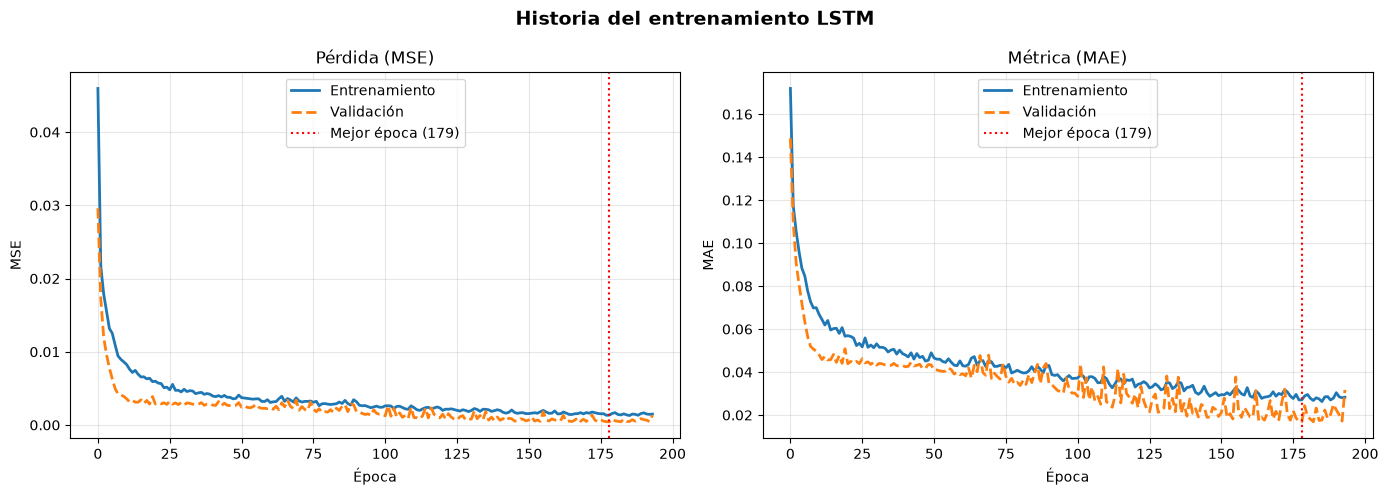

In [12]:
# Gráfico de la historia del entrenamiento
fig, axes = plt.subplots(1, 2, figsize=(14, 5))

for ax, metrica, titulo, etiqueta in zip(axes, ["loss", "mae"], ["Pérdida (MSE)", "Métrica (MAE)"], ["MSE", "MAE"]):
    ax.plot(history.history[metrica], label="Entrenamiento", linewidth=2)
    ax.plot(history.history[f"val_{metrica}"], label="Validación", linewidth=2, linestyle="--")
    ax.axvline(x=mejor_epoca, color="red", linestyle=":", label=f"Mejor época ({mejor_epoca + 1})")
    ax.set(title=titulo, xlabel="Época", ylabel=etiqueta)
    ax.legend()
    ax.grid(True, alpha=0.3)

plt.suptitle("Historia del entrenamiento LSTM", fontsize=14, fontweight="bold")
plt.tight_layout()
plt.show()

**Interpretación**

- El error de entrenamiento y el de validación bajan rápidamente en las primeras épocas y luego se estabilizan. Las dos curvas se mantienen cerca, por lo que no hay señales de sobreajuste.
- El error de validación es menor que el de entrenamiento. Esto ocurre porque el dropout solo se aplica durante el entrenamiento, mientras que en la validación la red usa todas sus neuronas.
- La parada temprana recupera los pesos de la época con menor error de validación.

## Pronóstico a un paso y pronóstico recursivo

- En el **pronóstico a un paso**, cada día del periodo de prueba se pronostica con una ventana que contiene la demanda observada de los 14 días anteriores. Es el tipo de evaluación más común en los ejemplos de LSTM, pero supone que cada día conocemos la demanda real del día anterior.
- En el **pronóstico recursivo**, el modelo pronostica los 90 días desde el último día de entrenamiento. Cada pronóstico reemplaza a la demanda observada en la ventana del día siguiente, de modo que el modelo nunca ve la demanda real del periodo de prueba. Este es el mismo tipo de pronóstico que hace Prophet a 90 días, por lo que es la comparación justa entre los dos notebooks.

In [13]:
# Transformación inversa de la demanda (columna 0 del escalamiento)
def a_escala_original(valores):
    return np.asarray(valores) * scaler.data_range_[0] + scaler.data_min_[0]

y_real = df["Demand"].values[n_train:]

# Pronóstico a un paso
pred_un_paso = a_escala_original(model.predict(X_test, verbose=0).ravel())

# Pronóstico recursivo
serie = scaled_data.copy()
for t in range(n_train, n_total):
    ventana = serie[t - window:t][np.newaxis, ...]       # ventana de los 14 días anteriores
    serie[t, 0] = model.predict(ventana, verbose=0)[0, 0] # el pronóstico reemplaza la demanda del día t
pred_recursivo = a_escala_original(serie[n_train:, 0])

## Evaluación del modelo

- El MAE es el error absoluto medio, el RMSE es la raíz del error cuadrático medio y el MAPE es el error porcentual absoluto medio. Los tres se calculan en GWh sobre los 90 días de prueba.
- Como referencia usamos el **ingenuo estacional**, que repite la última semana observada del entrenamiento, igual que en el notebook de Prophet.

In [14]:
def metricas(y_real, y_pred):
    error = np.asarray(y_real) - np.asarray(y_pred)
    return {
        "MAE": np.mean(np.abs(error)),
        "RMSE": np.sqrt(np.mean(error ** 2)),
        "MAPE (%)": 100 * np.mean(np.abs(error / np.asarray(y_real))),
    }

ultima_semana = df["Demand"].values[n_train - 7:n_train]
pred_snaive = np.tile(ultima_semana, int(np.ceil(h / 7)))[:h]

resultados = pd.DataFrame({
    "Ingenuo estacional": metricas(y_real, pred_snaive),
    "LSTM recursivo (90 días)": metricas(y_real, pred_recursivo),
    "LSTM a un paso": metricas(y_real, pred_un_paso),
}).T.sort_values("RMSE").round(3)

resultados

,MAE,RMSE,MAPE (%)
LSTM a un paso,5.676,7.517,2.786
LSTM recursivo (90 días),8.419,12.959,4.241
Ingenuo estacional,10.776,15.196,5.343


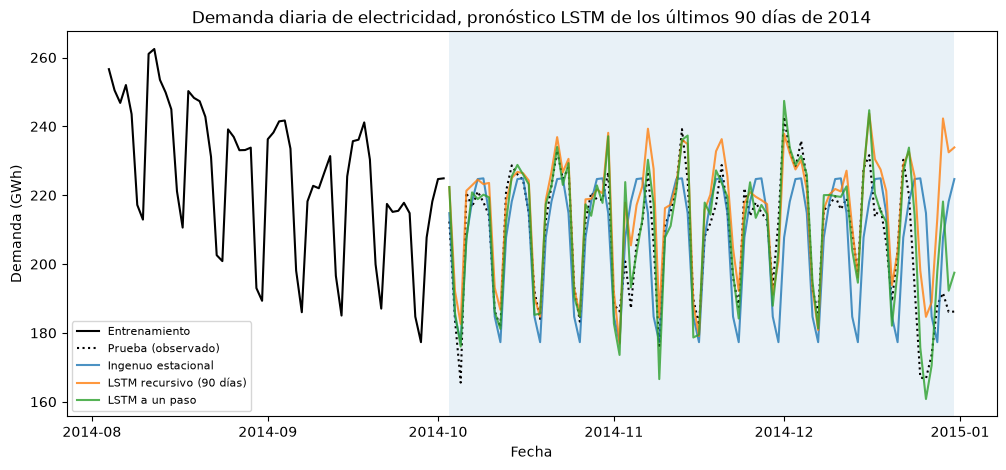

In [15]:
# Representación gráfica de los valores reales frente a los pronósticos
fechas_test = df.index[n_train:]

fig, ax = plt.subplots(figsize=(12, 5))
ax.plot(df.index[n_train - 60:n_train], df["Demand"].values[n_train - 60:n_train],
        color="black", label="Entrenamiento")
ax.plot(fechas_test, y_real, color="black", linestyle=":", label="Prueba (observado)")
ax.plot(fechas_test, pred_snaive, alpha=0.8, label="Ingenuo estacional")
ax.plot(fechas_test, pred_recursivo, alpha=0.8, label="LSTM recursivo (90 días)")
ax.plot(fechas_test, pred_un_paso, alpha=0.8, label="LSTM a un paso")
ax.axvspan(fechas_test[0], fechas_test[-1], alpha=0.1)
ax.set(xlabel="Fecha", ylabel="Demanda (GWh)",
       title="Demanda diaria de electricidad, pronóstico LSTM de los últimos 90 días de 2014")
ax.legend(fontsize=8)
plt.show()

## Conclusiones

- El pronóstico a un paso tiene el menor error de la tabla, con un RMSE de 7.5 GWh. Sin embargo, en cada día de prueba usa la demanda real del día anterior, por lo que no se puede comparar con un pronóstico a 90 días.
- El pronóstico recursivo a 90 días es la comparación justa. Su RMSE de 13.0 GWh y su MAPE de 4.2% son mejores que los del ingenuo estacional, pero peores que los del modelo Prophet con regresoras del otro notebook (RMSE de 8.0 GWh y MAPE de 3.0%), que usa la misma información y el mismo periodo de prueba.
- En el pronóstico recursivo los errores se acumulan, porque cada pronóstico se usa como entrada del siguiente. Los errores más grandes aparecen entre Navidad y Año Nuevo, cuando la demanda cae por las vacaciones. La red solo vio dos periodos de fin de año en el entrenamiento, mientras que Prophet modela los festivos y la estacionalidad anual de forma explícita.
- Este resultado coincide con lo que vimos en la presentación. Un modelo más complejo no siempre pronostica mejor, y por eso siempre se debe comparar con modelos más simples usando el mismo periodo de prueba y el mismo horizonte.
- Los pesos iniciales de la red son aleatorios. Aunque fijamos una semilla, los resultados pueden cambiar un poco entre computadores o versiones de TensorFlow.